# Chapitre 2 - Cours 4 : graphes de propriétés, Cypher et requêtes récursives en SQL

Le modèle document convient aux arbres, le relationnel aux relations plusieurs-à-un et
aux plusieurs-à-plusieurs simples. Quand **tout peut être relié à tout**, il devient
plus naturel de penser en **graphe**. Ce cours couvre la section *Graph-Like Data Models*
et ses sous-sections *Property Graphs*, *The Cypher Query Language* et *Graph Queries in
SQL*.

**Plan.**

1. Pourquoi des graphes ? Exemples, représentations, algorithmes.
2. Le graphe de propriétés.
3. Interroger par motifs : le langage Cypher.
4. Les requêtes de graphe en SQL : `WITH RECURSIVE`.

In [1]:
import json
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Pourquoi des graphes ? (section *Graph-Like Data Models*)

Un graphe a deux sortes d'objets : des **sommets** (nœuds, entités) et des **arêtes**
(relations, arcs). Beaucoup de données s'y prêtent :

- **graphes sociaux** : les sommets sont des personnes, les arêtes disent qui connaît qui ;
- **graphe du Web** : les sommets sont des pages, les arêtes des liens HTML ;
- **réseaux routiers ou ferrés** : les sommets sont des carrefours, les arêtes des
  tronçons.

Des algorithmes classiques opèrent sur ces graphes : le **plus court chemin** pour la
navigation routière, **PageRank** pour estimer la popularité d'une page web et classer
les résultats d'un moteur de recherche.

**Deux représentations.** La **liste d'adjacence** stocke pour chaque sommet les
identifiants de ses voisins ; la **matrice d'adjacence** est un tableau carré dont la
case $(i, j)$ vaut 1 s'il existe une arête de $i$ vers $j$. Pour un graphe de $n$
sommets et $m$ arêtes, la liste occupe $O(n + m)$ et la matrice $O(n^2)$ : les graphes
réels étant très **creux** (chacun n'a que quelques voisins), la liste est bien plus
compacte et permet de parcourir les voisins d'un sommet en temps proportionnel à son
degré.

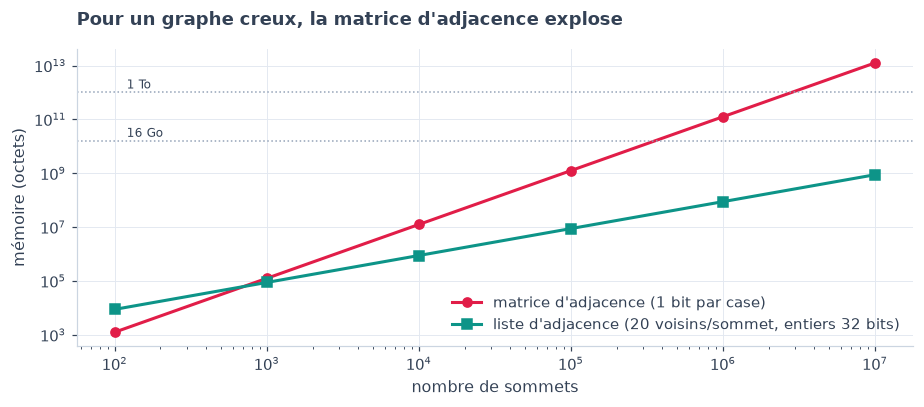

In [2]:
ns = np.array([1e2, 1e3, 1e4, 1e5, 1e6, 1e7])
deg = 20
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.loglog(ns, ns * ns / 8, marker="o", color=ROSE, label="matrice d'adjacence (1 bit par case)")
ax.loglog(ns, ns * 8 + ns * deg * 4, marker="s", color=TEAL, label=f"liste d'adjacence ({deg} voisins/sommet, entiers 32 bits)")
for y, txt in [(16e9, "16 Go"), (1e12, "1 To")]:
    ax.axhline(y, color=GRAY, ls=":", lw=1); ax.text(120, y * 1.4, txt, fontsize=8, color=SLATE)
ax.set_xlabel("nombre de sommets"); ax.set_ylabel("mémoire (octets)")
ax.set_title("Pour un graphe creux, la matrice d'adjacence explose")
ax.legend(); plt.tight_layout(); plt.show()

Illustrons un algorithme de graphe sur une liste d'adjacence : **PageRank** par
itération de puissance sur un petit graphe du Web synthétique (les pages populaires
reçoivent plus de liens). Le score d'une page est la probabilité qu'un internaute qui
clique au hasard (et repart parfois d'une page quelconque, avec probabilité 15 %) s'y
trouve.

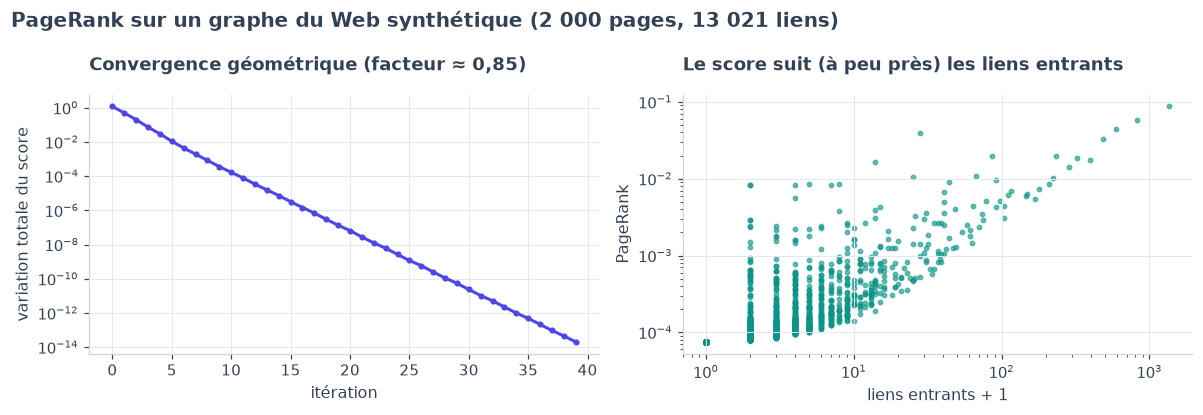

In [3]:
n_pages = 2000
pop = 1 / np.arange(1, n_pages + 1) ** 1.1
pop /= pop.sum()
liens = {p: set(rng.choice(n_pages, size=int(rng.integers(1, 15)), p=pop).tolist()) - {p} for p in range(n_pages)}

def pagerank(adj, n, d=0.85, iters=40):
    pr = np.full(n, 1 / n)
    hist = []
    for _ in range(iters):
        new = np.full(n, (1 - d) / n)
        for u, vs in adj.items():
            if vs:
                share = d * pr[u] / len(vs)
                for v in vs:
                    new[v] += share
            else:
                new += d * pr[u] / n
        hist.append(np.abs(new - pr).sum())
        pr = new
    return pr, hist

pr, hist = pagerank(liens, n_pages)
entrants = np.zeros(n_pages)
for u, vs in liens.items():
    for v in vs:
        entrants[v] += 1
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(hist, color=INDIGO, marker=".")
axes[0].set_xlabel("itération"); axes[0].set_ylabel("variation totale du score")
axes[0].set_title("Convergence géométrique (facteur ≈ 0,85)")
axes[1].scatter(entrants + 1, pr, s=8, color=TEAL, alpha=0.6)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("liens entrants + 1"); axes[1].set_ylabel("PageRank")
axes[1].set_title("Le score suit (à peu près) les liens entrants")
finish(fig, f"PageRank sur un graphe du Web synthétique ({fmt(n_pages)} pages, {fmt(sum(map(len, liens.values())))} liens)")

Les exemples ci-dessus sont **homogènes** (tous les sommets sont du même type). Un usage
tout aussi puissant des graphes est de ranger des objets **de types différents** dans une
même base. Facebook entretient ainsi un graphe unique dont les sommets sont des
personnes, des lieux, des événements, des commentaires, et dont les arêtes disent qui est
ami avec qui, quel commentaire porte sur quel message, qui a participé à quel
événement.

> **À retenir.** Un graphe, ce sont des sommets et des arêtes. La liste d'adjacence
> ($O(n + m)$) convient aux graphes creux et aux parcours ; la matrice ($O(n^2)$) aux
> calculs algébriques. Un graphe peut mêler des sommets et des arêtes de types variés.